In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
file_path = "/kaggle/input/datasets/samuelsemaya/e-commerce-customer-churn/data_ecommerce_customer_churn.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3941, 11)


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [3]:
target_column = 'Churn' if 'Churn' in df.columns else df.columns[-1]

X = df.drop(columns=[target_column])
Y = df[target_column]

# Convert target to binary values if needed
if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().str.lower()

    Y = Y.map({
        'yes': 1,
        'no': 0,
        'true': 1,
        'false': 0,
        '1': 1,
        '0': 0
    })

# Remove rows with missing target values
valid_rows = Y.notna()

X = X.loc[valid_rows]
Y = Y.loc[valid_rows].astype(int)

# Select numeric features
X = X.select_dtypes(include=np.number)

print("Features Shape:", X.shape)
print("Target Distribution:")
print(Y.value_counts())

Features Shape: (3941, 8)
Target Distribution:
Churn
0    3267
1     674
Name: count, dtype: int64


In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (3152, 8)
Testing Shape: (789, 8)


In [5]:
# Handle missing values
imputer = SimpleImputer(strategy='mean')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add bias column
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

Y_train = np.array(Y_train)
Y_test = np.array(Y_test)

print("Preprocessing Completed!")
print("X_train_bias:", X_train_bias.shape)
print("X_test_bias:", X_test_bias.shape)

Preprocessing Completed!
X_train_bias: (3152, 9)
X_test_bias: (789, 9)


In [7]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [8]:
def binary_cross_entropy(Y, probabilities):
    epsilon = 1e-8

    probabilities = np.clip(
        probabilities,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        Y * np.log(probabilities) +
        (1 - Y) * np.log(1 - probabilities)
    )

    return loss

In [23]:
def logistic_adam(
    X,
    Y,
    learning_rate=0.01,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8,
    epochs=150
):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)

    # First moment: Momentum
    m = np.zeros(n_features)

    # Second moment: Squared gradients
    v = np.zeros(n_features)

    train_losses = []
    train_accuracies = []

    for epoch in range(1, epochs + 1):

        # Forward propagation
        predictions = sigmoid(np.dot(X, weights))

        # Calculate gradient
        gradient = np.dot(
            X.T,
            (predictions - Y)
        ) / n_samples

        # Update first moment
        m = beta1 * m + (1 - beta1) * gradient

        # Update second moment
        v = beta2 * v + (1 - beta2) * (gradient ** 2)

        # Bias correction
        m_hat = m / (1 - beta1 ** epoch)
        v_hat = v / (1 - beta2 ** epoch)

        # Update weights
        weights -= (
            learning_rate * m_hat /
            (np.sqrt(v_hat) + epsilon)
        )

        # Calculate loss after weight update
        updated_probabilities = sigmoid(
            np.dot(X, weights)
        )

        epoch_loss = binary_cross_entropy(
            Y,
            updated_probabilities
        )

        # Calculate training accuracy
        train_predictions = (
            updated_probabilities >= 0.5
        ).astype(int)

        epoch_accuracy = accuracy_score(
            Y,
            train_predictions
        )

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch}/{epochs} | "
                f"Loss: {epoch_loss:.4f} | "
                f"Accuracy: {epoch_accuracy:.4f}"
            )

    return weights, train_losses, train_accuracies

In [24]:
weights_adam, losses_adam, accuracies_adam = logistic_adam(
    X_train_bias,
    Y_train,
    learning_rate=0.01,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8,
    epochs=150
)

print("\nAdam Optimizer Training Completed!")

Epoch 1/150 | Loss: 0.6853 | Accuracy: 0.7157
Epoch 10/150 | Loss: 0.6269 | Accuracy: 0.7157
Epoch 20/150 | Loss: 0.5822 | Accuracy: 0.7341
Epoch 30/150 | Loss: 0.5489 | Accuracy: 0.7602
Epoch 40/150 | Loss: 0.5209 | Accuracy: 0.7862
Epoch 50/150 | Loss: 0.4972 | Accuracy: 0.8039
Epoch 60/150 | Loss: 0.4772 | Accuracy: 0.8192
Epoch 70/150 | Loss: 0.4599 | Accuracy: 0.8312
Epoch 80/150 | Loss: 0.4448 | Accuracy: 0.8382
Epoch 90/150 | Loss: 0.4315 | Accuracy: 0.8433
Epoch 100/150 | Loss: 0.4199 | Accuracy: 0.8487
Epoch 110/150 | Loss: 0.4098 | Accuracy: 0.8541
Epoch 120/150 | Loss: 0.4008 | Accuracy: 0.8528
Epoch 130/150 | Loss: 0.3929 | Accuracy: 0.8569
Epoch 140/150 | Loss: 0.3859 | Accuracy: 0.8598
Epoch 150/150 | Loss: 0.3797 | Accuracy: 0.8626

Adam Optimizer Training Completed!


In [25]:
# Predict probabilities
Y_pred_prob = sigmoid(
    np.dot(X_test_bias, weights_adam)
)

# Convert probabilities into classes
Y_pred = (Y_pred_prob >= 0.5).astype(int)

print("Adam Predictions Completed!")

Adam Predictions Completed!


In [26]:
test_loss = binary_cross_entropy(
    Y_test,
    Y_pred_prob
)

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred, zero_division=0)
recall = recall_score(Y_test, Y_pred, zero_division=0)
f1 = f1_score(Y_test, Y_pred, zero_division=0)

print("========== ADAM OPTIMIZER RESULTS ==========")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"Test Loss: {test_loss:.4f}")

print("============================================")

========== ADAM OPTIMIZER RESULTS ==========
Accuracy:  0.8606
Precision: 0.6168
Recall:    0.4889
F1-Score:  0.5455
Test Loss: 0.3774


In [27]:
adam_results = pd.DataFrame({
    'Optimizer': ['Adam'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1-Score': [f1],
    'Test Loss': [test_loss]
})

adam_results.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Test Loss': '{:.4f}'
}).set_caption('Adam Optimizer - Performance Evaluation')

,Optimizer,Accuracy,Precision,Recall,F1-Score,Test Loss
0,Adam,0.8606,0.6168,0.4889,0.5455,0.3774


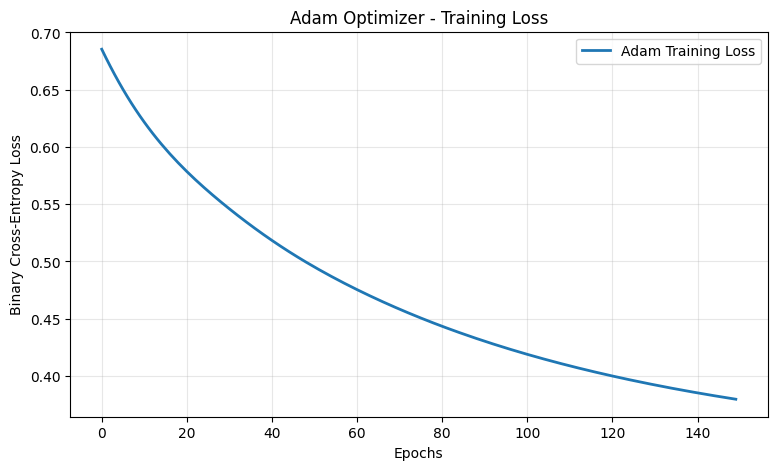

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    losses_adam,
    label='Adam Training Loss',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Adam Optimizer - Training Loss')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

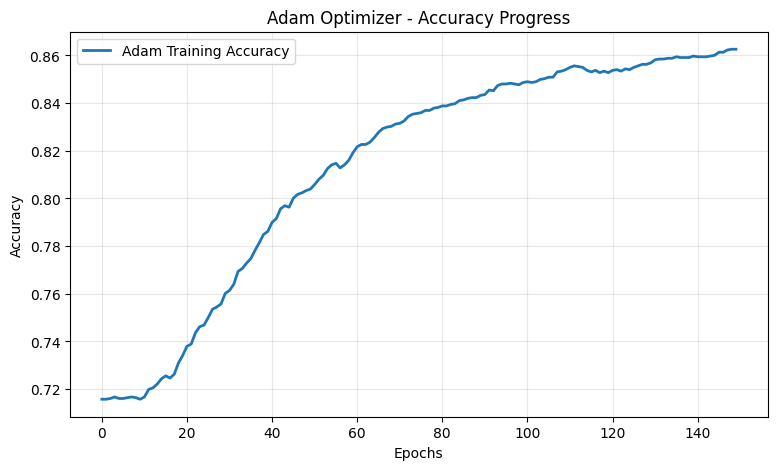

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    accuracies_adam,
    label='Adam Training Accuracy',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Adam Optimizer - Accuracy Progress')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

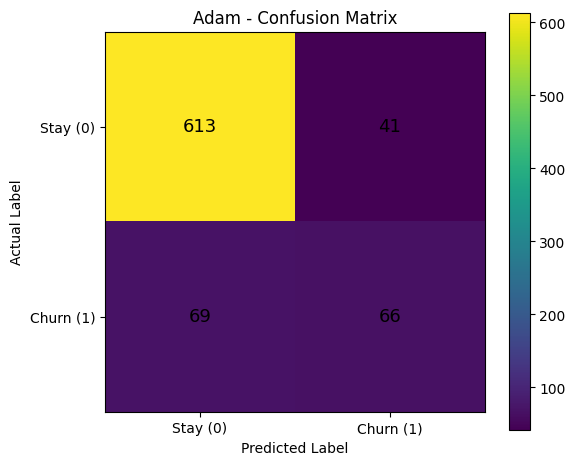

In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation='nearest')

plt.title('Adam - Confusion Matrix')
plt.colorbar()

plt.xticks([0, 1], ['Stay (0)', 'Churn (1)'])
plt.yticks([0, 1], ['Stay (0)', 'Churn (1)'])

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha='center',
            va='center',
            fontsize=13
        )

plt.tight_layout()
plt.show()

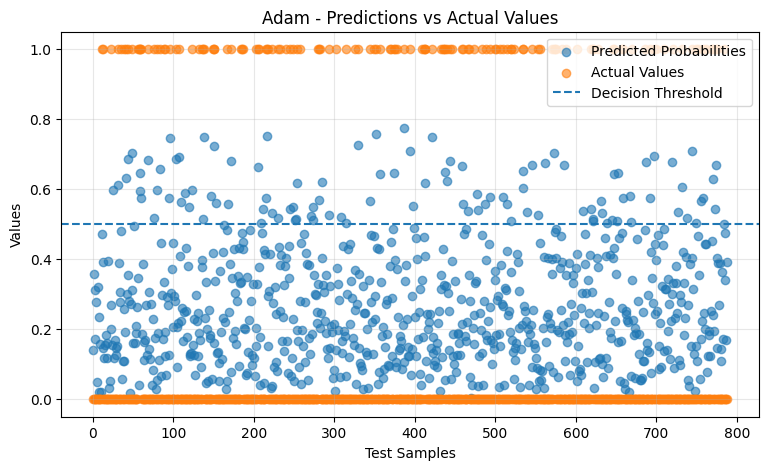

In [31]:
plt.figure(figsize=(9, 5))

plt.scatter(
    range(len(Y_test)),
    Y_pred_prob,
    label='Predicted Probabilities',
    alpha=0.6
)

plt.scatter(
    range(len(Y_test)),
    Y_test,
    label='Actual Values',
    alpha=0.6
)

plt.axhline(
    y=0.5,
    linestyle='--',
    label='Decision Threshold'
)

plt.xlabel('Test Samples')
plt.ylabel('Values')
plt.title('Adam - Predictions vs Actual Values')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
adam_parameters = pd.DataFrame({
    'Parameter': [
        'Learning Rate',
        'Beta 1',
        'Beta 2',
        'Epsilon',
        'Epochs'
    ],
    'Value': [
        0.01,
        0.9,
        0.999,
        1e-8,
        150
    ]
})

adam_parameters

,Parameter,Value
0,Learning Rate,1.000000e-02
1,Beta 1,9.000000e-01
2,Beta 2,9.990000e-01
3,Epsilon,1.000000e-08
4,Epochs,1.500000e+02
